In [6]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch

signals = pd.read_parquet('../data/processed/signals_PVS1_left.parquet')
windows = pd.read_csv('../data/processed/windows_PVS1_left.csv')

valid_ids = windows[windows['valid']].index
win_id = valid_ids[10]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


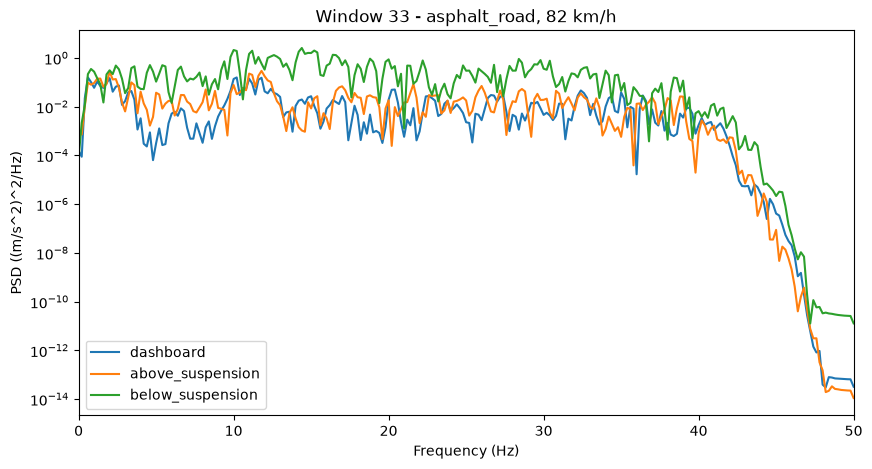

In [14]:
seg = signals[signals['window'] == win_id]
surface = windows.loc[win_id, 'surface']
speed_kmh = windows.loc[win_id, 'speed_mean']*3.6

positions = ['dashboard', 'above_suspension', 'below_suspension']
fs = 100

fig, ax = plt.subplots(figsize=(10,5))
for pos in positions:
    f, Pxx = welch(seg[f'acc_z_{pos}_filt'].to_numpy(), fs = fs, nperseg = 500)
    ax.semilogy(f, Pxx, label=pos)

ax.set_xlim(0,50)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD ((m/s^2)^2/Hz)')
ax.set_title(f'Window {win_id} - {surface}, {speed_kmh:.0f} km/h')
ax.legend()
plt.show()

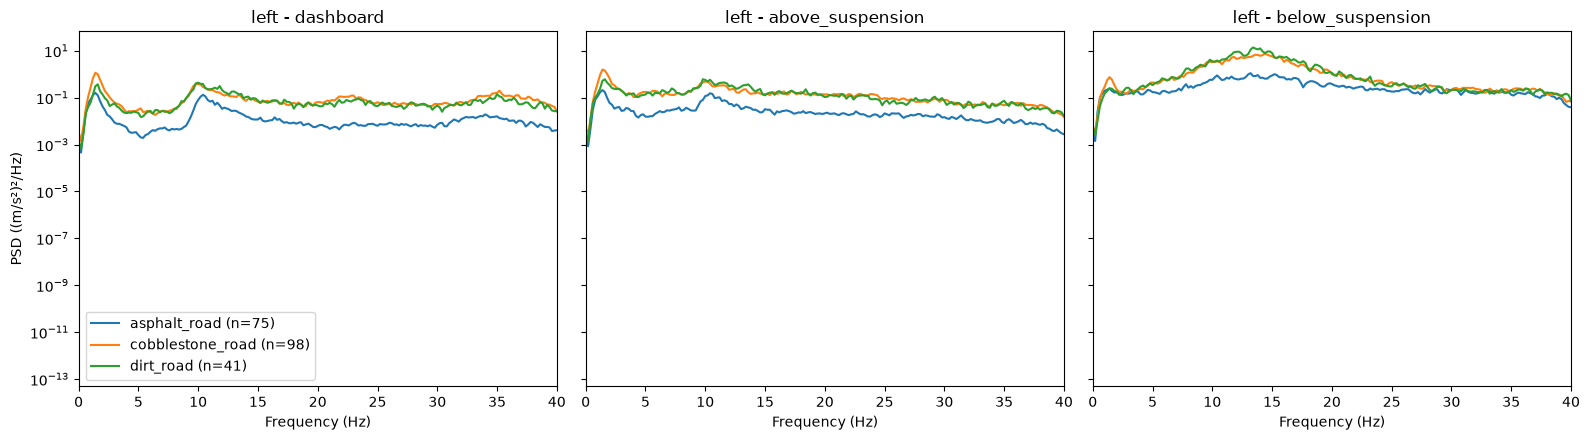

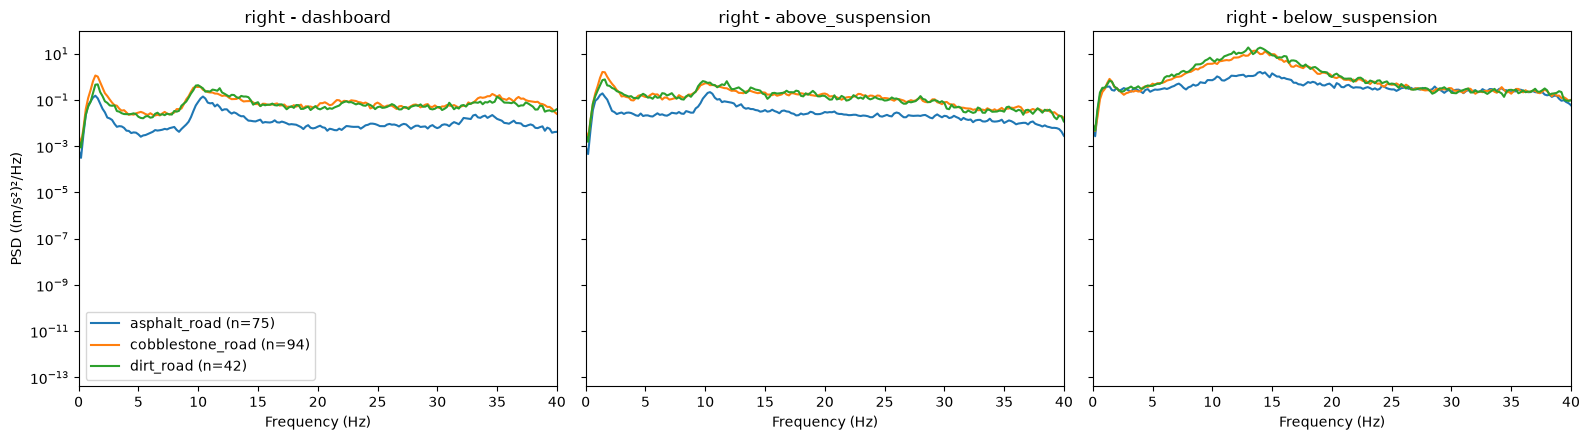

In [15]:
from src.spectral import mean_psd

data={}
for side in ['left', 'right']:
    signals = pd.read_parquet(f'../data/processed/signals_PVS1_{side}.parquet')
    windows = pd.read_csv(f'../data/processed/windows_PVS1_{side}.csv', index_col='window')
    data[side] = (signals, windows)

surfaces = ['asphalt_road', 'cobblestone_road', 'dirt_road']

for side, (signals, windows) in data.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for ax, pos in zip(axes, positions):
        for surf in surfaces:
            ids = windows[windows['valid'] & (windows['surface'] == surf)].index
            f, P = mean_psd(signals, ids, f'acc_z_{pos}_filt')
            ax.semilogy(f, P, label = f'{surf} (n={len(ids)})')
        ax.set_title(f'{side} - {pos}')
        ax.set_title(f'{side} - {pos}')
        ax.set_xlim(0, 40)
        ax.set_xlabel('Frequency (Hz)')
    axes[0].set_ylabel('PSD ((m/s²)²/Hz)')
    axes[0].legend()
    plt.tight_layout()
    plt.show()